In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split,GridSearchCV
from imblearn.over_sampling import SMOTE  # imblearn library can be installed using pip install imblearn
from imblearn.pipeline import Pipeline
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import classification_report
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# Importing dataset and examining it
dataset = pd.read_csv("Telco_Customer.csv")
pd.set_option('display.max_columns', None) # to make sure you can see all the columns in output window
print(dataset.head())
print(dataset.shape)
print(dataset.info())
print(dataset.describe())

# Drop ID Column
dataset = dataset.drop(columns=["customerID"])
print(dataset.info())

# Convert TotalCharges to numerical
dataset["TotalCharges"] = pd.to_numeric(dataset["TotalCharges"], errors="coerce")

# Drop rows with missing TotalCharges
dataset = dataset[dataset["TotalCharges"].notnull()].copy()

# Converting Categorical features into Numerical features
dataset['Churn'] = dataset['Churn'].map({'Yes':1, 'No':0})
dataset['gender'] = dataset['gender'].map({'Female':1, 'Male':0})
dataset['Partner'] = dataset['Partner'].map({'Yes':1, 'No':0})
dataset['Dependents'] = dataset['Dependents'].map({'Yes':1, 'No':0})
dataset['PhoneService'] = dataset['PhoneService'].map({'Yes':1, 'No':0})
dataset['OnlineSecurity'] = dataset['OnlineSecurity'].map({'Yes':1, 'No':0, 'No internet service':0})
dataset['OnlineBackup'] = dataset['OnlineBackup'].map({'Yes':1, 'No':0, 'No internet service':0})
dataset['DeviceProtection'] = dataset['DeviceProtection'].map({'Yes':1, 'No':0, 'No internet service':0})
dataset['TechSupport'] = dataset['TechSupport'].map({'Yes':1, 'No':0, 'No internet service':0})
dataset['StreamingTV'] = dataset['StreamingTV'].map({'Yes':1, 'No':0, 'No internet service':0})
dataset['StreamingMovies'] = dataset['StreamingMovies'].map({'Yes':1, 'No':0, 'No internet service':0})
dataset['PaperlessBilling'] = dataset['PaperlessBilling'].map({'Yes':1, 'No':0})
print(dataset.info())

# One-hot encoding categorical variables
categorical_features = ['TenureBand', 'MultipleLines', 'InternetService', 'Contract', 'PaymentMethod']
final_data = pd.get_dummies(dataset, columns = categorical_features)
print(final_data.info())
print(final_data.head(2))

# Dividing dataset into label and feature sets
X = final_data.drop('Churn', axis = 1) # Features
Y = final_data['Churn'] # Labels
print(type(X))
print(type(Y))
print(X.shape)
print(Y.shape)

# Normalizing numerical features so that each feature has mean 0 and variance 1
feature_scaler = StandardScaler()
X_scaled = feature_scaler.fit_transform(X)

# Splitting data into training and test sets
X_train, X_test, Y_train, Y_test = train_test_split(X_scaled, Y, test_size=0.2, random_state=42, stratify=Y)

### Implementing Logistic Regression
# Tuning eta0, max_iter, alpha, and l1_ratio parameters and implementing cross-validation using Grid Search
model = Pipeline([
        ('balancing', SMOTE(random_state = 101)),   # Synthetic Minority Oversampling Technique
        ('classification', SGDClassifier(loss = 'log_loss', penalty = 'elasticnet', random_state = 1))
    ])
grid_param = {'classification__eta0': [.001,.01,.1,1,10,100], 'classification__max_iter' : [100,500,1000], 'classification__alpha': [.001, .01,.1, 1,10,100], 'classification__l1_ratio': [0,0.3,0.5,0.7,1]}

gd_sr = GridSearchCV(estimator=model, param_grid=grid_param, scoring='recall', cv=5)

"""
In the above GridSearchCV(), scoring parameter should be set as follows:
scoring = 'accuracy' when you want to maximize prediction accuracy
scoring = 'recall' when you want to minimize false negatives
scoring = 'precision' when you want to minimize false positives
scoring = 'f1' when you want to balance false positives and false negatives (place equal emphasis on minimizing both)
"""

gd_sr.fit(X_train, Y_train)

print('-----------------------------------------------------------------------')
print('-----------------------------------------------------------------------')

best_parameters = gd_sr.best_params_
print("Best parameters: ", best_parameters)

best_result = gd_sr.best_score_ # Mean cross-validated score of the best_estimator
print("Best result: ", best_result)

# Evaluating the best model on test set
final_model = gd_sr.best_estimator_
Y_pred = final_model.predict(X_test)
print(classification_report(Y_test, Y_pred))


   customerID  gender  SeniorCitizen Partner Dependents TenureBand  tenure  \
0  2967-MXRAV    Male              0     Yes        Yes        New       1   
1  8992-CEUEN  Female              0      No         No        New       1   
2  9318-NKNFC    Male              0      No         No        New       1   
3  9975-SKRNR    Male              0      No         No        New       1   
4  1423-BMPBQ  Female              0     Yes        Yes        New       1   

  PhoneService MultipleLines InternetService       OnlineSecurity  \
0          Yes            No              No  No internet service   
1          Yes            No              No  No internet service   
2          Yes            No              No  No internet service   
3          Yes            No              No  No internet service   
4          Yes            No              No  No internet service   

          OnlineBackup     DeviceProtection          TechSupport  \
0  No internet service  No internet service  No 

Churn
No     64.425
Yes    79.650
Name: MonthlyCharges, dtype: float64


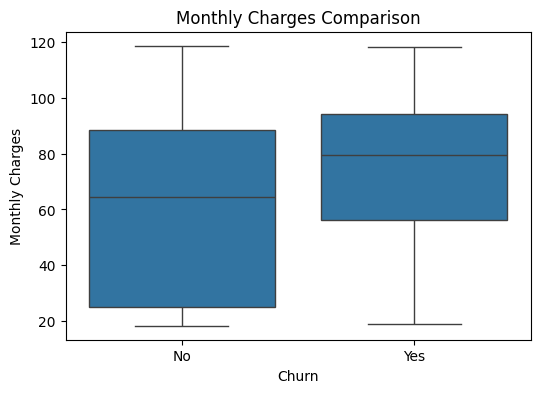

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Importing dataset
dataset = pd.read_csv('Telco_Customer.csv')

# Calculate Median
medians = dataset.groupby('Churn')['MonthlyCharges'].median()
print(medians)

plt.figure(figsize=(6,4))
sns.boxplot(x='Churn', y='MonthlyCharges', data=dataset)

plt.title('Monthly Charges Comparison')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')

plt.show()